# NYC Rent — data exploration

**Part A** — StreetEasy (target + market features). **Part B** — NYC city datasets (supply, evictions, transit, NTA map).

Loads every source file from `data_source/` and surfaces what we need to decide how to use the data:
coverage, missing values, noise, and a first look at whether each metric carries signal for future rent changes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd()                  # project folder: notebooks + data we create
SRC_DIR = DATA_DIR / "data_source"     # original downloads, never edited
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.spines.top": False, "axes.spines.right": False})
sorted(p.name for p in SRC_DIR.glob("*.csv"))

['2020_Neighborhood_Tabulation_Areas_(NTAs)_20261027.csv',
 'Evictions_20261027.csv',
 'Housing_Database_Project_Level_Files_20261027.csv',
 'MTA_Subway_Stations_20261027.csv',
 'discountShare_All.csv',
 'medianAskingPrice_All.csv',
 'medianAskingRent_All.csv',
 'priceCutShare_All.csv',
 'rentalIndex_All.csv',
 'rentalInventory_All.csv']

# Part A — StreetEasy
## 1. What is in each StreetEasy file

In [2]:
rows = []
SE_FILES = ["medianAskingRent_All.csv", "rentalInventory_All.csv", "discountShare_All.csv",
            "medianAskingPrice_All.csv", "priceCutShare_All.csv", "rentalIndex_All.csv"]
for name in SE_FILES:                                 # city datasets are covered in Part B
    p = SRC_DIR / name
    df = pd.read_csv(p)
    if "areaType" in df.columns:                      # wide: one row per area, one column per month
        months = [c for c in df.columns if c[:2] in ("19", "20")]
        rows.append(dict(file=p.name, layout="area x month (wide)", areas=len(df),
                         area_types=df.areaType.value_counts().to_dict(),
                         first=months[0], last=months[-1], n_months=len(months),
                         missing_share=round(df[months].isna().mean().mean(), 3)))
    else:                                             # rentalIndex: one row per month, one column per area
        rows.append(dict(file=p.name, layout="month x area (long)", areas=df.shape[1] - 1,
                         area_types=list(df.columns[1:]), first=df.month.iloc[0], last=df.month.iloc[-1],
                         n_months=len(df), missing_share=round(df.iloc[:, 1:].isna().mean().mean(), 3)))
pd.DataFrame(rows)

,file,layout,areas,area_types,first,last,n_months,missing_share
0,medianAskingRent_All.csv,area x month (wide),182,"{'neighborhood': 176, 'borough': 5, 'city': 1}",2010-01,2026-09,201,0.104
1,rentalInventory_All.csv,area x month (wide),182,"{'neighborhood': 176, 'borough': 5, 'city': 1}",2010-01,2026-09,201,0.000
2,discountShare_All.csv,area x month (wide),182,"{'neighborhood': 176, 'borough': 5, 'city': 1}",2010-01,2026-09,201,0.104
3,medianAskingPrice_All.csv,area x month (wide),182,"{'neighborhood': 176, 'borough': 5, 'city': 1}",2010-01,2026-09,201,0.039
4,priceCutShare_All.csv,area x month (wide),182,"{'neighborhood': 176, 'borough': 5, 'city': 1}",2010-01,2026-09,201,0.039
5,rentalIndex_All.csv,month x area (long),4,"[Brooklyn, Manhattan, NYC, Queens]",2007-01,2026-09,237,0.101


## 2. Load into one table (area × month)

In [3]:
def load_wide(name, col):
    df = pd.read_csv(SRC_DIR / name)
    long = df.melt(id_vars=["areaName", "Borough", "areaType"], var_name="month", value_name=col)
    long["date"] = pd.to_datetime(long.month, format="%Y-%m")
    return long.drop(columns="month")

KEYS = ["areaName", "Borough", "areaType", "date"]
data = (load_wide("medianAskingRent_All.csv", "rent")
        .merge(load_wide("rentalInventory_All.csv", "inventory"), on=KEYS)
        .merge(load_wide("discountShare_All.csv", "discount_share"), on=KEYS)
        # sales side
        .merge(load_wide("medianAskingPrice_All.csv", "sale_price"), on=KEYS, how="left")
        .merge(load_wide("priceCutShare_All.csv", "sale_cut_share"), on=KEYS, how="left")
        .sort_values(["areaType", "areaName", "date"]).reset_index(drop=True))
data["price_to_rent"] = data.sale_price / (data.rent * 12)   # years of rent to buy

index = pd.read_csv(SRC_DIR / "rentalIndex_All.csv")
index["date"] = pd.to_datetime(index.month, format="%Y-%m")
index = index.drop(columns="month").set_index("date")

print(data.shape)
data[data.areaType == "neighborhood"].head()

(36582, 10)


,areaName,Borough,areaType,rent,date,inventory,discount_share,sale_price,sale_cut_share,price_to_rent
1206,Astoria,Queens,neighborhood,1600.0,2010-01-01,99.0,0.090909,469000.0,0.300000,24.427083
1207,Astoria,Queens,neighborhood,1650.0,2010-02-01,98.0,0.081633,490000.0,0.043478,24.747475
1208,Astoria,Queens,neighborhood,1600.0,2010-03-01,106.0,0.037736,499000.0,0.033520,25.989583
1209,Astoria,Queens,neighborhood,1600.0,2010-04-01,78.0,0.012821,447000.0,0.022222,23.281250
1210,Astoria,Queens,neighborhood,1662.0,2010-05-01,57.0,0.035088,445000.0,0.035088,22.312475


In [4]:
data.groupby("areaType")[["rent", "inventory", "discount_share", "sale_price", "sale_cut_share", "price_to_rent"]].describe().T.round(3)

areaType                  borough         city  neighborhood
rent           count     1005.000      201.000  3.155700e+04
               mean      2541.080     3091.085  2.551290e+03
               std        766.751      436.238  1.192874e+03
               min       1050.000     2475.000  5.500000e+02
               25%       1950.000     2800.000  1.800000e+03
               50%       2450.000     2950.000  2.250000e+03
               75%       3100.000     3400.000  2.999000e+03
               max       4995.000     4200.000  2.500000e+04
inventory      count     1005.000      201.000  3.537600e+04
               mean      6261.313    31306.886  1.775490e+02
               std       7386.722    12265.588  4.286890e+02
               min          2.000    11967.000  0.000000e+00
               25%        297.000    23634.000  3.000000e+00
               50%       3013.000    30508.000  2.300000e+01
               75%      11570.000    37937.000  1.410000e+02
               max      40354.000    73560.000  6.110000e+03
discount_share count     1005.000      201.000  3.155700e+04
               mean         0.124        0.158  1.200000e-01
               std          0.064        0.042  1.300000e-01
               min          0.000        0.086  0.000000e+00
               25%          0.084        0.129  0.000000e+00
               50%          0.121        0.153  1.070000e-01
               75%          0.159        0.181  1.710000e-01
               max          0.786        0.322  1.000000e+00
sale_price     count     1005.000      201.000  3.396400e+04
               mean    760881.016   933469.318  8.861900e+05
               std     420225.524   178081.163  7.627998e+05
               min     245000.000   600000.000  4.675000e+04
               25%     429000.000   729999.000  4.350000e+05
               50%     649894.000   995000.000  6.990000e+05
               75%     969000.000  1079990.000  1.098000e+06
               max    1995000.000  1200000.000  1.980000e+07
sale_cut_share count     1005.000      201.000  3.396400e+04
               mean         0.089        0.094  8.300000e-02
               std          0.030        0.025  9.800000e-02
               min          0.000        0.021  0.000000e+00
               25%          0.066        0.077  0.000000e+00
               50%          0.087        0.093  7.100000e-02
               75%          0.109        0.110  1.180000e-01
               max          0.182        0.160  1.000000e+00
price_to_rent  count     1005.000      201.000  3.085700e+04
               mean        23.995       25.470  2.866900e+01
               std          8.177        5.423  1.698100e+01
               min          9.382       16.270  1.269000e+00
               25%         18.275       20.531  1.852500e+01
               50%         23.300       24.485  2.634400e+01
               75%         28.289       29.807  3.541000e+01
               max         50.232       36.883  7.674420e+02

## 3. Coverage

In [5]:
nb = data[data.areaType == "neighborhood"].copy()
metrics = ["rent", "inventory", "discount_share", "sale_price", "sale_cut_share"]
nb.assign(year=nb.date.dt.year).groupby("year")[metrics].apply(lambda g: g.isna().mean()).round(3).T

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rent,0.352,0.260,0.209,0.179,0.127,0.100,0.065,0.054,0.054,0.042,0.054,0.054,0.053,0.043,0.059,0.055,0.064
inventory,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
discount_share,0.352,0.260,0.209,0.179,0.127,0.100,0.065,0.054,0.054,0.042,0.054,0.054,0.053,0.043,0.059,0.055,0.064
sale_price,0.089,0.081,0.078,0.055,0.047,0.045,0.049,0.030,0.022,0.017,0.026,0.025,0.018,0.018,0.025,0.023,0.028
sale_cut_share,0.089,0.081,0.078,0.055,0.047,0.045,0.049,0.030,0.022,0.017,0.026,0.025,0.018,0.018,0.025,0.023,0.028


In [6]:
since15 = nb[nb.date >= "2015-01-01"]
complete = since15.groupby(["areaName", "Borough"])[["rent", "discount_share", "sale_price", "sale_cut_share"]].apply(lambda g: g.notna().all())
print("neighborhoods with a complete series since 2015:")
print(complete.sum().to_string(), "\n")
complete.groupby("Borough").sum()

neighborhoods with a complete series since 2015:
rent              125
discount_share    125
sale_price        150
sale_cut_share    150 



,rent,discount_share,sale_price,sale_cut_share
Borough,,,,
Bronx,23,23,23,23
Brooklyn,43,43,48,48
Manhattan,31,31,30,30
Queens,28,28,49,49


In [7]:
# Is a missing rent just a month with no listings?
print("median inventory when rent missing:", nb.loc[nb.rent.isna(), "inventory"].median())
print("median inventory when rent present:", nb.loc[nb.rent.notna(), "inventory"].median())
print("min inventory with rent present:  ", nb.loc[nb.rent.notna(), "inventory"].min())

median inventory when rent missing: 0.0
median inventory when rent present: 35.0
min inventory with rent present:   1.0


## 4. Listing volume and noise

In [8]:
nb["rent_yoy"] = nb.groupby("areaName").rent.pct_change(12, fill_method=None)
nbhd = (nb[nb.date >= "2015-01-01"].groupby(["areaName", "Borough"])
          .agg(med_inventory=("inventory", "median"), med_rent=("rent", "median")).reset_index())
vol = nb[(nb.date >= "2016-01-01") & (nb.date < "2020-01-01")].groupby("areaName").rent_yoy.std().rename("yoy_sd_2016_19")
nbhd = nbhd.merge(vol, on="areaName", how="left")
nbhd["inv_bucket"] = pd.cut(nbhd.med_inventory, [-1, 10, 20, 50, 100, np.inf], labels=["<=10", "10-20", "20-50", "50-100", ">100"])

nbhd.groupby("inv_bucket", observed=True).agg(neighborhoods=("areaName", "size"),
                                               median_yoy_sd=("yoy_sd_2016_19", "median"),
                                               median_rent=("med_rent", "median")).round(3)

,neighborhoods,median_yoy_sd,median_rent
inv_bucket,,,
<=10,60,0.278,2150.0
10-20,16,0.132,1862.5
20-50,20,0.090,2080.0
50-100,17,0.087,2229.0
>100,63,0.057,3000.0


In [9]:
pd.crosstab(nbhd.Borough, nbhd.inv_bucket, margins=True)

inv_bucket,<=10,10-20,20-50,50-100,>100,All
Borough,,,,,,
Bronx,22,11,5,2,2,42
Brooklyn,8,0,8,5,27,48
Manhattan,2,0,0,6,24,32
Queens,28,5,7,4,10,54
All,60,16,20,17,63,176


## 5. Rent Index vs. median asking rent

The index (repeat-listing method) tracks the same units over time, so it is not affected by changes in which units are listed.
If YoY changes in the median track the index closely at borough level, the median is a usable target.

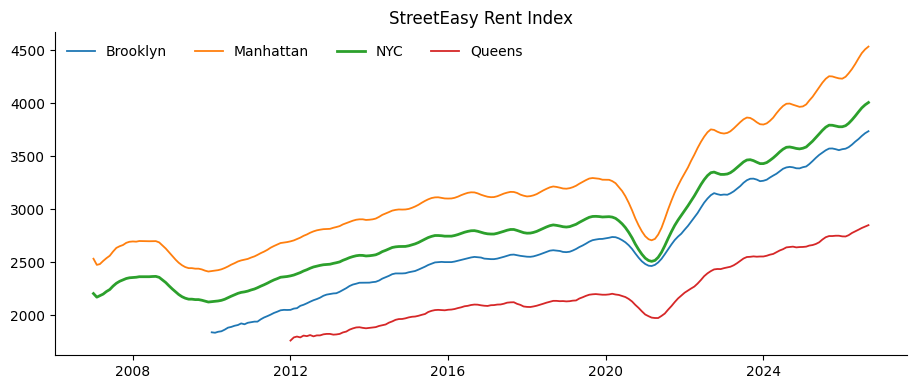

Brooklyn    2010-01-01
Manhattan   2007-01-01
NYC         2007-01-01
Queens      2012-01-01
Name: first available, dtype: datetime64[ns]

In [10]:
fig, ax = plt.subplots()
for c in index.columns:
    ax.plot(index.index, index[c], label=c, lw=2 if c == "NYC" else 1.3)
ax.set_title("StreetEasy Rent Index"); ax.legend(frameon=False, ncol=4); plt.show()
index.notna().idxmax().rename("first available")

In [11]:
areas = {"NYC": "NYC", "Manhattan": "Manhattan", "Brooklyn": "Brooklyn", "Queens": "Queens"}
cmp = []
for idx_col, area in areas.items():
    med = data[(data.areaName == area) & (data.areaType.isin(["city", "borough"]))].set_index("date").rent
    both = pd.DataFrame({"median_yoy": med.pct_change(12, fill_method=None),
                         "index_yoy": index[idx_col].pct_change(12, fill_method=None)}).dropna()
    both = both[both.index >= "2015-01-01"]
    cmp.append(dict(area=area, months=len(both), corr=both.corr().iloc[0, 1],
                    mean_abs_gap_pp=(both.median_yoy - both.index_yoy).abs().mean() * 100,
                    median_yoy_sd=both.median_yoy.std() * 100, index_yoy_sd=both.index_yoy.std() * 100))
pd.DataFrame(cmp).round(2)

,area,months,corr,mean_abs_gap_pp,median_yoy_sd,index_yoy_sd
0,NYC,141,0.93,3.30,10.04,7.00
1,Manhattan,141,0.98,3.37,12.41,8.26
2,Brooklyn,141,0.94,2.42,7.76,5.34
3,Queens,141,0.90,2.67,6.94,5.07


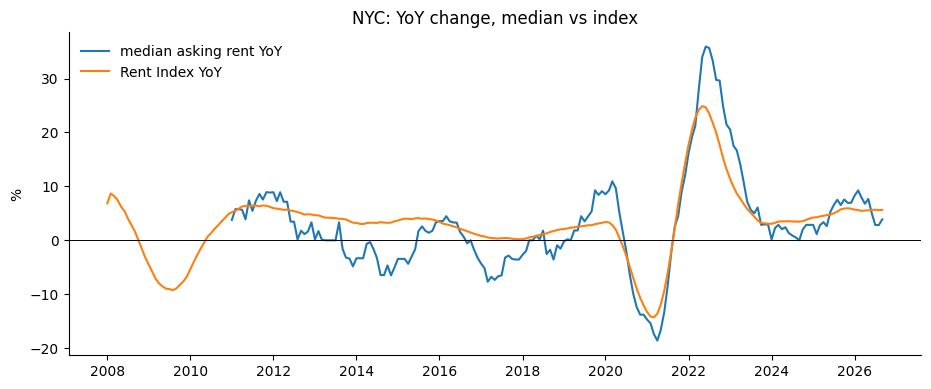

In [12]:
med_nyc = data[data.areaType == "city"].set_index("date").rent
fig, ax = plt.subplots()
ax.plot(med_nyc.pct_change(12, fill_method=None) * 100, label="median asking rent YoY")
ax.plot(index.NYC.pct_change(12, fill_method=None) * 100, label="Rent Index YoY")
ax.axhline(0, color="k", lw=.7); ax.set_ylabel("%"); ax.set_title("NYC: YoY change, median vs index"); ax.legend(frameon=False); plt.show()

## 6. Share of rent cuts (discount_share)

Candidate leading indicator: when more landlords cut prices, demand is softening.
Quick check: does today's discount share correlate with the **next 12 months'** rent change?

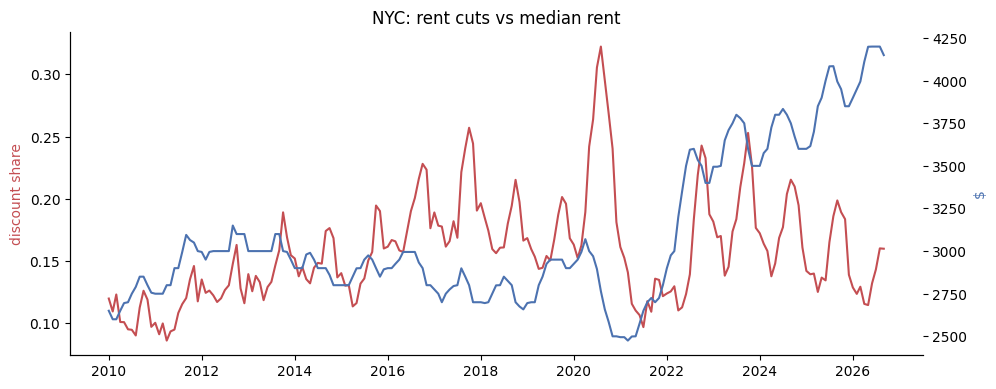

In [13]:
city = data[data.areaType == "city"].set_index("date")
fig, ax1 = plt.subplots()
ax1.plot(city.discount_share, color="#C44E52", label="share of listings with a rent cut")
ax2 = ax1.twinx(); ax2.plot(city.rent, color="#4C72B0", label="median asking rent")
ax1.set_ylabel("discount share", color="#C44E52"); ax2.set_ylabel("$", color="#4C72B0")
ax1.set_title("NYC: rent cuts vs median rent"); plt.show()

In [14]:
MIN_INVENTORY = 20
keep = nbhd.loc[nbhd.med_inventory >= MIN_INVENTORY, "areaName"]
nb["rent_3m"] = nb.groupby("areaName").rent.transform(lambda s: s.rolling(3, min_periods=3).mean())
nb["fwd_12m"] = nb.groupby("areaName").rent_3m.transform(lambda s: s.shift(-12) / s - 1)
nb["past_12m"] = nb.groupby("areaName").rent_3m.transform(lambda s: s / s.shift(12) - 1)
nb["inv_yoy"] = nb.groupby("areaName").inventory.pct_change(12, fill_method=None)
nb["sale_price_yoy"] = nb.groupby("areaName").sale_price.pct_change(12, fill_method=None)

sub = nb[nb.areaName.isin(keep) & (nb.date >= "2015-01-01")].dropna(subset=["fwd_12m"])
# Remove the city-wide move each month so we only measure differences between neighborhoods
demean = lambda s: s - sub.groupby("date")[s.name].transform("median")
spearman = lambda a, b: a.rank().corr(b.rank())   # rank correlation without scipy
feats = ["discount_share", "past_12m", "inv_yoy", "inventory",
         "sale_price_yoy", "sale_cut_share", "price_to_rent"]
signal = pd.DataFrame({
    "coverage": [sub[f].notna().mean() for f in feats],
    "corr_raw": [spearman(sub[f], sub.fwd_12m) for f in feats],
    "corr_vs_other_nbhds_same_month": [spearman(demean(sub[f]), demean(sub["fwd_12m"])) for f in feats],
}, index=feats).round(3)
print(f"{len(keep)} neighborhoods with median inventory >= {MIN_INVENTORY}, {len(sub):,} rows")
signal

100 neighborhoods with median inventory >= 20, 12,900 rows


,coverage,corr_raw,corr_vs_other_nbhds_same_month
discount_share,1.000,-0.206,-0.106
past_12m,1.000,-0.181,-0.308
inv_yoy,1.000,-0.004,-0.055
inventory,1.000,-0.037,-0.025
sale_price_yoy,0.985,-0.064,-0.059
sale_cut_share,0.987,0.011,-0.041
price_to_rent,0.987,-0.016,0.027


## 6b. Sales-side coverage in the neighborhoods we keep

Sales listings are thinner than rentals, so check how often the sales metrics exist where our target exists.

In [15]:
cov = (sub.groupby("Borough")[["sale_price", "sale_cut_share"]].apply(lambda g: g.notna().mean()).round(2))
cov.loc["ALL"] = sub[["sale_price", "sale_cut_share"]].notna().mean().round(2)
cov

,sale_price,sale_cut_share
Borough,,
Bronx,0.96,0.96
Brooklyn,1.00,1.00
Manhattan,0.97,0.97
Queens,1.00,1.00
ALL,0.99,0.99


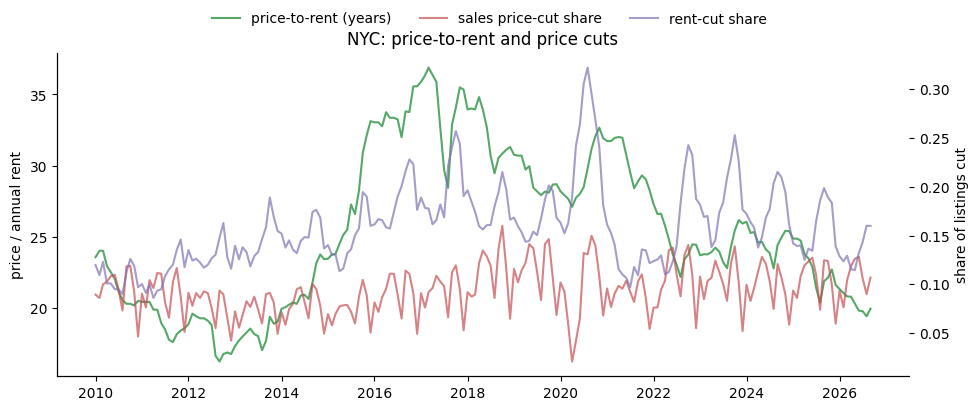

In [16]:
fig, ax1 = plt.subplots()
ax1.plot(city.price_to_rent, color="#55A868", label="price-to-rent (years)")
ax2 = ax1.twinx(); ax2.plot(city.sale_cut_share, color="#C44E52", alpha=.7, label="sales price-cut share")
ax2.plot(city.discount_share, color="#8172B2", alpha=.7, label="rent-cut share")
ax1.set_ylabel("price / annual rent"); ax2.set_ylabel("share of listings cut")
fig.legend(frameon=False, ncol=3, loc="upper center"); ax1.set_title("NYC: price-to-rent and price cuts"); plt.show()

## 7. The candidate target

In [17]:
print(sub.fwd_12m.describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
city_part = sub.groupby("date").fwd_12m.transform("median")
print("\nvariance total:", round(sub.fwd_12m.var(), 4),
      "| after removing city-wide median:", round((sub.fwd_12m - city_part).var(), 4))

count    12900.000
mean         0.045
std          0.110
min         -0.363
5%          -0.112
25%         -0.014
50%          0.034
75%          0.088
95%          0.243
max          0.842
Name: fwd_12m, dtype: float64

variance total: 0.0122 | after removing city-wide median: 0.0069


## 8. Seasonality (city level)

In [18]:
mom = city.rent.pct_change(fill_method=None)
mom = mom[mom.index.year.isin(range(2015, 2020)) | (mom.index.year >= 2023)]
seas = pd.DataFrame({"rent_mom_%": mom.groupby(mom.index.month).mean() * 100,
                     "discount_share": city.discount_share.groupby(city.index.month).mean(),
                     "inventory": city.inventory.groupby(city.index.month).mean()})
seas.round(2)

,rent_mom_%,discount_share,inventory
date,,,
1,0.53,0.15,28216.88
2,0.33,0.14,27141.47
3,0.39,0.14,29283.18
4,2.75,0.13,29660.94
5,1.65,0.14,32812.94
6,0.79,0.15,35005.18
7,0.99,0.15,36816.59
8,0.24,0.17,35810.06
9,-1.22,0.18,32153.35


## 9. Summary — StreetEasy

In [19]:
print(f"Months: {data.date.min():%Y-%m} -> {data.date.max():%Y-%m}")
print(f"Neighborhoods: {nb.areaName.nunique()} total, {complete['rent'].sum()} with complete rent since 2015, "
      f"{len(keep)} with median inventory >= {MIN_INVENTORY}")
print("Kept neighborhoods by borough:", nbhd[nbhd.areaName.isin(keep)].Borough.value_counts().to_dict())
print(f"Rent Index available for: {list(index.columns)} (no neighborhood level)")
print(f"Target rows (kept nbhds, 2015+, with 12m forward): {len(sub):,}")

Months: 2010-01 -> 2026-09
Neighborhoods: 176 total, 125 with complete rent since 2015, 100 with median inventory >= 20
Kept neighborhoods by borough: {'Brooklyn': 40, 'Manhattan': 30, 'Queens': 21, 'Bronx': 9}
Rent Index available for: ['Brooklyn', 'Manhattan', 'NYC', 'Queens'] (no neighborhood level)
Target rows (kept nbhds, 2015+, with 12m forward): 12,900


# Part B — NYC city datasets

Everything here has to end up at **StreetEasy neighborhood × month**. Every city dataset carries an NTA (official neighborhood) field and/or coordinates, so the path is: city data → NTA → StreetEasy neighborhood.

In [20]:
num = lambda s: pd.to_numeric(s.astype(str).str.replace(",", ""), errors="coerce")   # numbers come as text with commas

FILES = {
    "nta":      "2020_Neighborhood_Tabulation_Areas_(NTAs)_20261027.csv",
    "housing":  "Housing_Database_Project_Level_Files_20261027.csv",
    "evict":    "Evictions_20261027.csv",
    "subway":   "MTA_Subway_Stations_20261027.csv",
}
raw = {k: pd.read_csv(SRC_DIR / f, low_memory=False) for k, f in FILES.items()}
pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1]} for k, v in raw.items()}).T

,rows,columns
nta,262,12
housing,111909,67
evict,136185,20
subway,496,19


## 10. NTA map (the official neighborhoods)

In [21]:
nta = raw["nta"]
print(len(nta), "NTAs | geometry stored as WKT text in 'the_geom'")
print("NTAType (0 = residential; others = parks, cemeteries, airports...):", nta.NTAType.value_counts().to_dict())
nta[["NTA2020", "NTAName", "BoroName", "NTAType"]].head()

262 NTAs | geometry stored as WKT text in 'the_geom'
NTAType (0 = residential; others = parks, cemeteries, airports...): {0: 197, 9: 40, 7: 14, 6: 8, 8: 2, 5: 1}


,NTA2020,NTAName,BoroName,NTAType
0,BK0101,Greenpoint,Brooklyn,0
1,BK0102,Williamsburg,Brooklyn,0
2,BK0103,South Williamsburg,Brooklyn,0
3,BK0104,East Williamsburg,Brooklyn,0
4,BK0201,Brooklyn Heights,Brooklyn,0


## 11. Housing Database — new supply

DCP's cleaned record of every residential job since 2010 (new buildings, alterations, demolitions), with net units, completion date and **NTA2020 code already attached**.

In [22]:
h = raw["housing"].copy()
h["net_units"] = num(h.ClassANet)
h["complete_date"] = pd.to_datetime(h.DateComplt, errors="coerce")
print("job types:", h.Job_Type.value_counts().to_dict())
print("status:", h.Job_Status.value_counts().to_dict())
print("missing NTA2020:", round(h.NTA2020.isna().mean(), 4))
done = h[h.Job_Status.str.startswith("5")]
print("completed jobs:", len(done), "| missing completion date:", round(done.complete_date.isna().mean(), 4))

job types: {'Alteration': 63090, 'New Building': 35188, 'Demolition': 13631}
status: {'5. Completed Construction': 68073, '3. Permitted for Construction': 17081, '1. Filed Application': 11091, '9. Withdrawn': 9957, '2. Approved Application': 5704, '4. Partially Completed Construction': 3}
missing NTA2020: 0.0001
completed jobs: 68073 | missing completion date: 0.0


In [23]:
units_by_year = done.groupby([done.complete_date.dt.year, "Job_Type"]).net_units.sum().unstack().fillna(0).astype(int)
units_by_year["net_total"] = units_by_year.sum(axis=1)
units_by_year

Job_Type,Alteration,Demolition,New Building,net_total
complete_date,,,,
2010,1554,-897,22869,23526
2011,1551,-873,17234,17912
2012,1827,-1058,9692,10461
2013,1456,-1367,14452,14541
2014,836,-1548,13107,12395
2015,2340,-2348,15594,15586
2016,2353,-2013,23451,23791
2017,2549,-2161,25472,25860
2018,2242,-1671,28638,29209


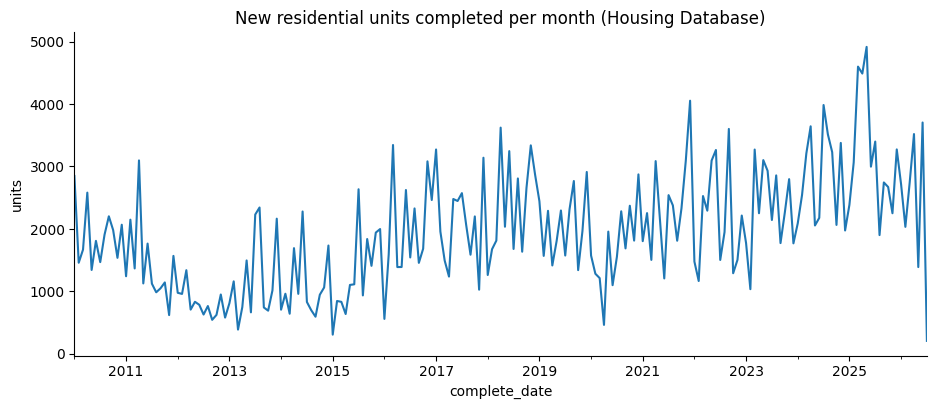

NTAs with any completions since 2015: 203 of 262
share of all net units in the top 20 NTAs: 0.44


NTA2020  NTAName20                                   
BK0601   Carroll Gardens-Cobble Hill-Gowanus-Red Hook     5205.0
BX0401   Concourse-Concourse Village                      5227.0
BK0302   Bedford-Stuyvesant (East)                        5273.0
MN0402   Hell's Kitchen                                   6197.0
QN0105   Queensbridge-Ravenswood-Dutch Kills              6347.0
BX0101   Mott Haven-Port Morris                           6627.0
BK0301   Bedford-Stuyvesant (West)                        6812.0
BK0203   Fort Greene                                      7027.0
QN1201   Jamaica                                          7568.0
MN0401   Chelsea-Hudson Yards                             7633.0
MN0101   Financial District-Battery Park City             8488.0
BK0101   Greenpoint                                       9345.0
BK0102   Williamsburg                                     9423.0
BK0202   Downtown Brooklyn-DUMBO-Boerum Hill             11854.0
QN0201   Long Island City-Hunters Po

In [24]:
nb_done = done[done.Job_Type == "New Building"]
monthly = nb_done.set_index("complete_date").net_units.resample("MS").sum()
ax = monthly["2010":].plot(title="New residential units completed per month (Housing Database)")
ax.set_ylabel("units"); plt.show()

since15 = done[done.complete_date >= "2015-01-01"]
per_nta = since15.groupby(["NTA2020", "NTAName20"]).net_units.sum().sort_values()
print("NTAs with any completions since 2015:", (per_nta != 0).sum(), "of", nta.shape[0])
print("share of all net units in the top 20 NTAs:", round(per_nta.tail(20).sum() / per_nta.sum(), 2))
per_nta.tail(15)

In [25]:
pipeline = h[h.Job_Status.str[:1].isin(["1", "2", "3"]) & (h.Job_Type == "New Building")]
print("units in the pipeline (filed / approved / permitted, not complete):", int(pipeline.net_units.sum()))
pipeline.groupby("Job_Status").net_units.agg(["count", "sum"])

units in the pipeline (filed / approved / permitted, not complete): 167352


,count,sum
Job_Status,,
1. Filed Application,3404,69734.0
2. Approved Application,1307,18106.0
3. Permitted for Construction,3949,79512.0


## 12. Certificates of Occupancy — dropped

We checked the two DOB Certificate of Occupancy files and removed them: COs are re-issued many times per job (temporary renewals),
the old file has a 2012 backlog spike and the new file a 2021 migration spike. The Housing Database is built from the same DOB records,
already de-duplicated and cleaned, so it replaces them. Median Days on Market (sales) was also dropped: no signal and weaker coverage.

## 13. Evictions

In [26]:
ev = raw["evict"].copy()
ev["date"] = pd.to_datetime(ev["Executed Date"], errors="coerce")
ev = ev[ev["Residential/Commercial"] == "Residential"]
print("residential evictions:", len(ev), "| missing NTA/coordinates:", round(ev.NTA.isna().mean(), 3))
by_year = ev.groupby(ev.date.dt.year).size()
by_year.to_frame("residential_evictions").T

residential evictions: 124320 | missing NTA/coordinates: 0.064


date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
residential_evictions,20803,19988,17036,3064,160,4029,12025,15461,17791,13963


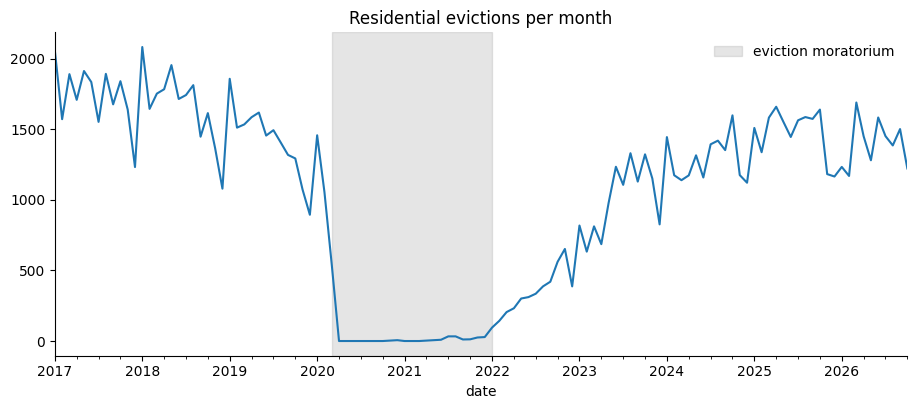

NTA
Central Harlem North-Polo Grounds    2626
East New York                        2558
Crown Heights North                  2435
East Concourse-Concourse Village     2309
Bedford Park-Fordham North           2247
Williamsbridge-Olinville             2199
Mount Hope                           2076
University Heights-Morris Heights    1980
Flatbush                             1907
Morrisania-Melrose                   1715
Name: count, dtype: int64

In [27]:
ax = ev.set_index("date").resample("MS").size().plot(title="Residential evictions per month")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2022-01-15"), color="grey", alpha=.2, label="eviction moratorium")
ax.legend(frameon=False); plt.show()
ev.NTA.value_counts().head(10)

## 14. Subway stations

In [28]:
sub_st = raw["subway"]
print(len(sub_st), "stops |", sub_st["Complex ID"].nunique(), "station complexes")
sub_st.Borough.value_counts()

496 stops | 445 station complexes


Borough
Bk    169
M     153
Q      83
Bx     70
SI     21
Name: count, dtype: int64

## 15. Linking test — StreetEasy names vs NTA names

How many of our 100 StreetEasy neighborhoods match an NTA name exactly, match part of a combined NTA name (e.g. "Greenpoint" in "Williamsburg-Greenpoint"), or need manual mapping?

In [29]:
nta_full = set(nta.NTAName.str.lower())
nta_parts = {p.strip().lower() for name in nta.NTAName for p in name.replace("(", "-").replace(")", "").split("-")}
def match_type(name):
    n = name.lower()
    return "exact" if n in nta_full else "part of NTA name" if n in nta_parts else "manual"
link = pd.DataFrame({"areaName": list(keep)})
link["match"] = link.areaName.map(match_type)
print(link.match.value_counts().to_dict())
sorted(link[link.match == "manual"].areaName)

{'part of NTA name': 46, 'exact': 42, 'manual': 12}


['Bedford-Stuyvesant',
 'Central Harlem',
 'Central Park South',
 'Columbia St Waterfront District',
 'Gramercy Park',
 'Greenwood',
 'Midtown East',
 'Midtown West',
 'Nolita',
 'Prospect Park South',
 'Rockaway All',
 'Stuyvesant Town/PCV']

## 16. Summary — city data

In [30]:
print(f"Housing DB: {len(done):,} completed jobs, NTA attached to {1 - h.NTA2020.isna().mean():.2%}; "
      f"net units 2015-2025: {int(units_by_year.loc[2015:2025, 'net_total'].sum()):,}")
print(f"Pipeline (not yet complete): {int(pipeline.net_units.sum()):,} units")
print(f"Evictions: {len(ev):,} residential, {ev.date.min():%Y-%m} -> {ev.date.max():%Y-%m}, NTA missing {ev.NTA.isna().mean():.1%}")
print(f"Subway: {sub_st['Complex ID'].nunique()} complexes")
print("Name linking:", link.match.value_counts().to_dict())

Housing DB: 68,073 completed jobs, NTA attached to 99.99%; net units 2015-2025: 309,320
Pipeline (not yet complete): 167,352 units
Evictions: 124,320 residential, 2017-01 -> 2026-10, NTA missing 6.4%
Subway: 445 complexes
Name linking: {'part of NTA name': 46, 'exact': 42, 'manual': 12}


# Part C — Linking city data to StreetEasy neighborhoods

`se_nta_mapping.csv` (in this folder) maps each StreetEasy neighborhood to one or more NTAs.
- **match**: exact name / part of NTA name / manual
- **confidence**: high / medium / low — review the medium and low rows

Direction: **city data (NTA) → StreetEasy neighborhood**. Rent data is never split.
- One StreetEasy neighborhood covering several NTAs (Williamsburg ← Williamsburg + South + East Williamsburg): the NTAs are added together.
- Several StreetEasy neighborhoods inside one NTA (DUMBO, Boerum Hill, Downtown Brooklyn ← one NTA): we do **not** split counts.
  Each gets the NTA's *density* (per km²), i.e. "conditions in the surrounding area". They end up with identical city features — the honest answer, since we can't see inside the NTA.

- **shares_nta**: 1 = this StreetEasy neighborhood shares an NTA with another StreetEasy neighborhood (candidate for a future merge); 0 = clean link
- **merge_group**: the neighborhoods that would be merged together (same as areaName when shares_nta = 0)

Edit the CSV by hand if a row is wrong and re-run from here.

In [31]:
mapping = pd.read_csv(DATA_DIR / "se_nta_mapping.csv")
print(mapping.areaName.nunique(), "StreetEasy neighborhoods ->", mapping.NTA2020.nunique(), "NTAs |",
      "unknown NTA codes:", (~mapping.NTA2020.isin(nta.NTA2020)).sum())
print("rows by match:", mapping.match.value_counts().to_dict())
kept_map = mapping[mapping.areaName.isin(keep)]
print("our 100 kept neighborhoods by confidence:", kept_map.drop_duplicates("areaName").confidence.value_counts().to_dict())
print("our 100 kept neighborhoods by shares_nta:", kept_map.drop_duplicates("areaName").shares_nta.value_counts().to_dict())
kept_map[kept_map.confidence != "high"]

176 StreetEasy neighborhoods -> 170 NTAs | unknown NTA codes: 0
rows by match: {'part of NTA name': 96, 'exact name': 70, 'manual': 46}
our 100 kept neighborhoods by confidence: {'high': 87, 'medium': 12, 'low': 1}
our 100 kept neighborhoods by shares_nta: {0: 68, 1: 32}


,areaName,Borough,NTA2020,NTAName,match,confidence,note,merge_group,shares_nta
13,Fordham,Bronx,BX0503,Fordham Heights,manual,medium,adds Fordham Heights,Fordham / Morris Heights / University Heights,1
14,Fordham,Bronx,BX0701,University Heights (North)-Fordham,manual,medium,adds Fordham Heights,Fordham / Morris Heights / University Heights,1
17,Kingsbridge,Bronx,BX0801,Kingsbridge Heights-Van Cortlandt Village,manual,medium,adds Kingsbridge Heights,Kingsbridge / Marble Hill,1
18,Kingsbridge,Bronx,BX0802,Kingsbridge-Marble Hill,manual,medium,adds Kingsbridge Heights,Kingsbridge / Marble Hill,1
63,Columbia St Waterfront District,Brooklyn,BK0601,Carroll Gardens-Cobble Hill-Gowanus-Red Hook,manual,medium,small area inside the Carroll Gardens/Red Hook...,Carroll Gardens / Cobble Hill / Columbia St Wa...,1
75,East New York,Brooklyn,BK0501,Cypress Hills,manual,medium,adds Cypress Hills,East New York,0
76,East New York,Brooklyn,BK0502,East New York (North),manual,medium,adds Cypress Hills,East New York,0
77,East New York,Brooklyn,BK0503,East New York-New Lots,manual,medium,adds Cypress Hills,East New York,0
78,East New York,Brooklyn,BK0505,East New York-City Line,manual,medium,adds Cypress Hills,East New York,0
88,Greenwood,Brooklyn,BK0701,Windsor Terrace-South Slope,manual,medium,Greenwood Heights ~ South Slope NTA,Greenwood / Windsor Terrace,1


In [32]:
resid = nta[nta.NTAType == 0]
print("residential NTAs not linked to any StreetEasy neighborhood:", (~resid.NTA2020.isin(mapping.NTA2020)).sum(), "of", len(resid))
resid.loc[~resid.NTA2020.isin(mapping.NTA2020), ["NTA2020", "NTAName", "BoroName"]].groupby("BoroName").size()

residential NTAs not linked to any StreetEasy neighborhood: 27 of 197


BoroName
Bronx             4
Brooklyn          4
Queens            3
Staten Island    16
dtype: int64

## 17. Put points (evictions, subway stations) into 2020 NTAs

The NTA field inside the evictions file uses the older 2010 neighborhood names, so we place every point with its coordinates instead.
Point-in-polygon with matplotlib (no extra packages).

In [33]:
import re
from matplotlib.path import Path as MplPath

def wkt_rings(wkt):
    return [np.array([[float(v) for v in pt.split()] for pt in ring.split(",")])
            for ring in re.findall(r"\(([^()]+)\)", wkt)]

NTA_RINGS = {r.NTA2020: wkt_rings(r.the_geom) for r in nta.itertuples()}

def points_to_nta(lon, lat):
    pts = np.column_stack([lon, lat])
    out = np.full(len(pts), None, dtype=object)
    ok = ~np.isnan(pts).any(axis=1)
    for code_, rings in NTA_RINGS.items():
        allpts = np.vstack(rings)
        (x0, y0), (x1, y1) = allpts.min(0), allpts.max(0)
        cand = ok & (pts[:, 0] >= x0) & (pts[:, 0] <= x1) & (pts[:, 1] >= y0) & (pts[:, 1] <= y1) & (out == None)
        if not cand.any():
            continue
        inside = sum(MplPath(r).contains_points(pts[cand]).astype(int) for r in rings) % 2 == 1   # even-odd handles holes
        idx = np.where(cand)[0][inside]
        out[idx] = code_
    return out

ev["NTA2020"] = points_to_nta(num(ev.Longitude).values, num(ev.Latitude).values)
sub_st["NTA2020"] = points_to_nta(num(sub_st["GTFS Longitude"]).values, num(sub_st["GTFS Latitude"]).values)
print("evictions placed in an NTA:", round(ev.NTA2020.notna().mean(), 3), "| subway stops placed:", round(sub_st.NTA2020.notna().mean(), 3))

evictions placed in an NTA: 0.936 | subway stops placed: 1.0


## 18. NTA × month features
- **new_units** — units in new buildings completed that month
- **net_units** — all job types (new + alterations − demolitions)
- **pipeline_units** — units in new buildings that had a permit but were not finished yet *at that month* (rebuilt from dates, so no look-ahead)
- **evictions** — residential evictions executed that month
- **subway_complexes** — static

In [34]:
months = pd.date_range("2010-01-01", "2026-09-01", freq="MS")
grid = pd.MultiIndex.from_product([nta.NTA2020, months], names=["NTA2020", "date"])

def monthly_count(df, date_col, value=None):
    d = df.dropna(subset=["NTA2020", date_col]).assign(date=lambda x: x[date_col].dt.to_period("M").dt.to_timestamp())
    s = d.groupby(["NTA2020", "date"])[value].sum() if value else d.groupby(["NTA2020", "date"]).size()
    return s.reindex(grid, fill_value=0)

feat = pd.DataFrame(index=grid)
feat["new_units"] = monthly_count(done[done.Job_Type == "New Building"], "complete_date", "net_units")
feat["net_units"] = monthly_count(done, "complete_date", "net_units")
feat["evictions"] = monthly_count(ev, "date")

# pipeline: +units at permit month, -units at completion month, cumulative
nbj = h[(h.Job_Type == "New Building") & h.Job_Status.str[:1].isin(["3", "4", "5"])].copy()
nbj["permit_date"] = pd.to_datetime(nbj.DatePermit, errors="coerce")
nbj = nbj[nbj.permit_date.notna() & ~(nbj.complete_date < "2010-01-01")]        # need a permit date; ignore jobs finished before our window
nbj["permit_date"] = nbj.permit_date.clip(lower=pd.Timestamp("2010-01-01"))     # permitted earlier = already in the pipeline in Jan 2010
starts = monthly_count(nbj.assign(u=nbj.net_units), "permit_date", "u")
ends = monthly_count(nbj[nbj.complete_date.notna()].assign(u=lambda x: x.net_units), "complete_date", "u")
feat["pipeline_units"] = (starts - ends).groupby(level="NTA2020").cumsum()

feat = feat.reset_index()
feat["subway_complexes"] = feat.NTA2020.map(sub_st.groupby("NTA2020")["Complex ID"].nunique()).fillna(0)
feat["area_km2"] = feat.NTA2020.map(dict(zip(nta.NTA2020, num(nta.Shape_Area) * 0.092903 / 1e6)))
print("pipeline never negative:", (feat.pipeline_units >= 0).all())
feat.groupby("date")[["new_units", "evictions", "pipeline_units"]].sum().loc[["2015-01-01", "2019-01-01", "2023-01-01", "2026-01-01"]]

pipeline never negative: True


,new_units,evictions,pipeline_units
date,,,
2015-01-01,307.0,0,59730.0
2019-01-01,2444.0,1735,82868.0
2023-01-01,1773.0,782,129479.0
2026-01-01,2717.0,1152,80807.0


## 19. Roll up to StreetEasy neighborhood × month and join

In [35]:
feat = feat.sort_values(["NTA2020", "date"])
gn = feat.groupby("NTA2020")
feat["new_units_12m"] = gn.new_units.transform(lambda s: s.rolling(12).sum())
feat["evictions_12m"] = gn.evictions.transform(lambda s: s.rolling(12).sum())

# full NTAs summed per StreetEasy neighborhood, then divided by their total area -> densities (no splitting)
f = feat.merge(mapping[["areaName", "NTA2020"]], on="NTA2020")
cols = ["new_units", "net_units", "new_units_12m", "pipeline_units", "evictions", "evictions_12m", "subway_complexes", "area_km2"]
se_feat = f.groupby(["areaName", "date"])[cols].sum().reset_index()
for c in ["new_units_12m", "pipeline_units", "evictions_12m", "subway_complexes"]:
    se_feat[c.replace("_units", "").replace("_complexes", "") + "_per_km2"] = se_feat[c] / se_feat.area_km2

panel = nb.merge(se_feat, on=["areaName", "date"], how="left")
print(panel.shape)
panel[panel.areaName.isin(keep) & (panel.date == "2025-09-01")][
    ["areaName", "Borough", "rent", "new_12m_per_km2", "pipeline_per_km2", "evictions_12m_per_km2", "subway_per_km2"]
].sort_values("new_12m_per_km2", ascending=False).round(1).head(10)

(35376, 28)


,areaName,Borough,rent,new_12m_per_km2,pipeline_per_km2,evictions_12m_per_km2,subway_per_km2
13454,Fort Greene,Brooklyn,4865.0,1620.7,475.8,30.1,2.5
19484,Long Island City,Queens,4555.0,938.9,853.8,22.2,1.6
16871,Inwood,Manhattan,3125.0,853.7,455.6,99.9,2.2
33353,West Harlem,Manhattan,3678.0,491.3,140.4,41.1,2.0
9032,DUMBO,Brooklyn,5480.0,480.3,1000.6,23.6,3.6
9635,Downtown Brooklyn,Brooklyn,4425.0,480.3,1000.6,23.6,3.6
2801,Boerum Hill,Brooklyn,4880.0,480.3,1000.6,23.6,3.6
27122,Red Hook,Brooklyn,4495.0,411.5,1087.9,5.7,0.5
7625,Columbia St Waterfront District,Brooklyn,4400.0,411.5,1087.9,5.7,0.5
5012,Carroll Gardens,Brooklyn,4950.0,411.5,1087.9,5.7,0.5


## 20. First signal check for the city features

Same test as Part A: rank correlation with the next-12-month rent change, raw and relative to other neighborhoods in the same month.
Evictions only from 2018 (data starts 2017 and we need 12 months of history).

In [36]:
test = panel[panel.areaName.isin(keep) & (panel.date >= "2015-01-01")].dropna(subset=["fwd_12m"]).copy()
test.loc[test.date < "2018-01-01", "evictions_12m_per_km2"] = np.nan
city_feats = ["new_12m_per_km2", "pipeline_per_km2", "evictions_12m_per_km2", "subway_per_km2"]
rel = lambda c: test[c] - test.groupby("date")[c].transform("median")
pd.DataFrame({
    "coverage": [test[c].notna().mean() for c in city_feats],
    "corr_raw": [spearman(test[c], test.fwd_12m) for c in city_feats],
    "corr_vs_other_nbhds_same_month": [spearman(rel(c), rel("fwd_12m")) for c in city_feats],
}, index=city_feats).round(3)

,coverage,corr_raw,corr_vs_other_nbhds_same_month
new_12m_per_km2,1.000,-0.008,-0.014
pipeline_per_km2,1.000,-0.005,-0.002
evictions_12m_per_km2,0.721,-0.356,-0.007
subway_per_km2,1.000,-0.023,-0.030


Reverse-causality check: do developers *finish* buildings where rents already rose? (correlation with the **past** 12-month change)

In [37]:
pd.Series({c: spearman(rel(c), rel("past_12m")) for c in city_feats}, name="corr_with_PAST_12m_vs_other_nbhds").round(3)

new_12m_per_km2          0.040
pipeline_per_km2        -0.026
evictions_12m_per_km2    0.015
subway_per_km2          -0.042
Name: corr_with_PAST_12m_vs_other_nbhds, dtype: float64

# Part D — Build the unified panel

One row per **StreetEasy neighborhood × month** (all 176 neighborhoods, 2010-01 → 2026-09).
Only data and features computed from the past — no forward-looking (target) columns yet.

In [38]:
P = panel.copy()
grp = mapping.drop_duplicates("areaName").set_index("areaName")
P["merge_group"] = P.areaName.map(grp.merge_group)
P["shares_nta"] = P.areaName.map(grp.shares_nta)
P["med_inventory"] = P.areaName.map(nbhd.set_index("areaName").med_inventory)
P["in_model"] = (P.med_inventory >= MIN_INVENTORY).astype(int)

# evictions data starts 2017-01: earlier months are unknown, not zero
P.loc[P.date < "2017-01-01", "evictions"] = np.nan
P.loc[P.date < "2017-12-01", "evictions_12m_per_km2"] = np.nan

# % change from a month with 0 listings is undefined (division by zero -> inf)
P["inv_yoy"] = P.inv_yoy.replace([np.inf, -np.inf], np.nan)

P["covid_period"] = P.date.between("2020-03-01", "2021-06-01").astype(int)
P["eviction_moratorium"] = P.date.between("2020-03-01", "2022-01-01").astype(int)

P = P.rename(columns={"discount_share": "rent_cut_share", "inv_yoy": "inventory_yoy",
                      "new_12m_per_km2": "new_units_12m_km2", "pipeline_per_km2": "pipeline_km2",
                      "evictions_12m_per_km2": "evictions_12m_km2", "subway_per_km2": "subway_km2"})
COLUMNS = ["areaName", "Borough", "date",
           "merge_group", "shares_nta", "area_km2",
           "med_inventory", "in_model",
           "rent", "inventory", "rent_cut_share", "sale_price", "sale_cut_share",
           "rent_3m", "past_12m", "inventory_yoy", "sale_price_yoy", "price_to_rent",
           "new_units", "net_units", "pipeline_units", "evictions", "subway_complexes",
           "new_units_12m_km2", "pipeline_km2", "evictions_12m_km2", "subway_km2",
           "covid_period", "eviction_moratorium"]
P = P[COLUMNS].sort_values(["areaName", "date"]).reset_index(drop=True)
assert not any(c.startswith("fwd") for c in P.columns)
P.to_csv(DATA_DIR / "nyc_rent_panel.csv", index=False)
print(P.shape, "-> nyc_rent_panel.csv")
print("rows with in_model = 1:", int(P.in_model.sum()), "| neighborhoods in model:", P[P.in_model == 1].areaName.nunique())

(35376, 29) -> nyc_rent_panel.csv
rows with in_model = 1: 20100 | neighborhoods in model: 100


In [39]:
P.isna().mean().round(3).rename("share_missing").to_frame().T

,areaName,Borough,date,merge_group,shares_nta,area_km2,med_inventory,in_model,rent,inventory,rent_cut_share,sale_price,sale_cut_share,rent_3m,past_12m,inventory_yoy,sale_price_yoy,price_to_rent,new_units,net_units,pipeline_units,evictions,subway_complexes,new_units_12m_km2,pipeline_km2,evictions_12m_km2,subway_km2,covid_period,eviction_moratorium
share_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.108,0.0,0.108,0.04,0.04,0.156,0.246,0.164,0.113,0.128,0.0,0.0,0.0,0.418,0.0,0.0,0.0,0.473,0.0,0.0,0.0


In [40]:
P[(P.areaName == "Williamsburg") & (P.date >= "2025-07-01")].T

,34356,34357,34358,34359,34360,34361,34362,34363,34364,34365,34366,34367,34368,34369,34370
areaName,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg
Borough,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn,Brooklyn
date,2025-07-01 00:00:00,2025-08-01 00:00:00,2025-09-01 00:00:00,2025-10-01 00:00:00,2025-11-01 00:00:00,2025-12-01 00:00:00,2026-01-01 00:00:00,2026-02-01 00:00:00,2026-03-01 00:00:00,2026-04-01 00:00:00,2026-05-01 00:00:00,2026-06-01 00:00:00,2026-07-01 00:00:00,2026-08-01 00:00:00,2026-09-01 00:00:00
merge_group,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg,Williamsburg
shares_nta,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
area_km2,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274,8.949274
med_inventory,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0,1573.0
in_model,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
rent,4900.0,4950.0,4930.0,4795.0,4750.0,4750.0,4750.0,4700.0,4725.0,4800.0,4950.0,4999.0,5100.0,5119.0,5041.0
inventory,2132.0,2037.0,1780.0,1538.0,1218.0,1057.0,1042.0,1049.0,1419.0,1466.0,1531.0,1716.0,1904.0,1784.0,1334.0
